# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Abellana, Gian
- _Student No._: 2024-09545
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from matplotlib.colors import ListedColormap

# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

## 1. Setting Up the Ising Model

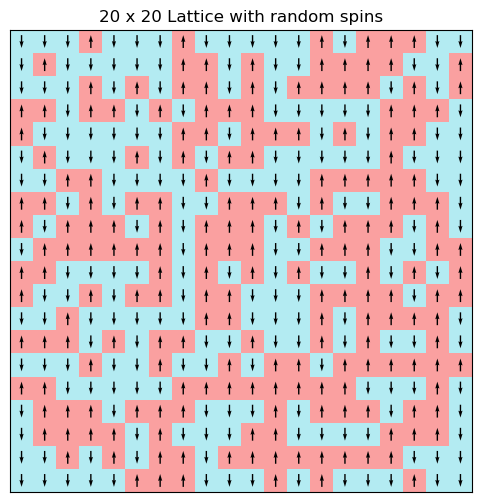

In [2]:
# 1. Create a 20 x 20 lattice with randomly initialized spins of +1 or -1

n = 20

rng = np.random.default_rng()
lattice = rng.choice([-1, 1], size = (n, n)) # choose between -1 or 1 randomly for each element

# 2. Plot the initial spin configuration

plt.figure(figsize = (6,6))
cmap = ListedColormap(["#B3EBF2", "#FAA0A0"])
plt.imshow(lattice, cmap = cmap, vmin = -1, vmax = 1, origin = 'lower', interpolation = 'nearest')

y, x = np.indices(lattice.shape)
plt.quiver(x, y, np.zeros_like(lattice), lattice, pivot = 'mid', angles = 'xy')
plt.xticks([])
plt.yticks([])
plt.title("20 x 20 Lattice with random spins")

# turning whatever is above into a function so i can create lattices
def createLattice(dim):
    rng = np.random.default_rng()
    lattice = rng.choice([-1, 1], size = (dim, dim))
    return lattice

In [3]:
# 3. Write a function to calculate the total energy using:

# consts
J = 1

def totalEnergy(lattice, J = 1):
    # H = -J sum_ij [S_ij (S_i+1, j + S_i, j+1)

    # for S_i+1, j, we can shift i (row) by 1
    # since periodic boundary conditions, i can just put the topmost row to the bottom row (the next neighbor of bottomest row is the topmost row)
    lattice_row_shift = np.roll(lattice, shift = -1, axis = 0)
    
    # do the same for column shift, shift leftest column to the rightest part
    lattice_col_shift = np.roll(lattice, shift = -1, axis = 1)
    
    # total shift term sum
    shift_sum = lattice_row_shift + lattice_col_shift
    
    # note: element wise multiplication
    product = lattice * shift_sum
    
    # sum up all the elements
    H = -J * np.sum(product)
    return H

energy = totalEnergy(lattice, J)

print(f"Energy = {energy}")

Energy = -4


## 2. Implementing the Metropolis Algorithm

In [4]:
# 1. Randomly select a spin S_i,j

# first we have to copy the lattice, in case we need it later
lattice2 = lattice.copy()

rand_i = rng.integers(0,n)
rand_j = rng.integers(0,n)

random_spin = lattice2[rand_i, rand_j]

print("---------------")
print("Selected Spin:")
print(f"Spin_{rand_i, rand_j} = {random_spin}")
print("---------------")

# 2. Flip its orientation
lattice2[rand_i, rand_j] = random_spin * -1

# 3. Calculate the energy change
old_energy = totalEnergy(lattice, J)
new_energy = totalEnergy(lattice2, J)

dH = new_energy - old_energy
print(f"Old energy = {old_energy}")
print(f"New energy = {new_energy}")
print(f"Change in energy = {dH}")
print("---------------")

# code above is for demonstration and debugging purposes, below is the function form so that i can reuse it
def perturb(lattice):
    lattice2 = lattice.copy()

    rand_i = rng.integers(0,n)
    rand_j = rng.integers(0,n)

    random_spin = lattice2[rand_i, rand_j]
    lattice2[rand_i, rand_j] = random_spin * -1

    old_energy = totalEnergy(lattice, J)
    new_energy = totalEnergy(lattice2, J)

    dH = new_energy - old_energy

    return dH, lattice2

---------------
Selected Spin:
Spin_(4, 9) = 1
---------------
Old energy = -4
New energy = 0
Change in energy = 4
---------------


In [5]:
# 4. Accept the flip with probability
# P_accept = min(1, exp(-delta_H/(k_B T)))

# consts:
J = 1
kB = 1
T = 1

# probability of acceptance from boltzmann distribution
P_accept = min(1, np.exp(-dH/(kB*T)))
# random roll from 0 to 1
roll = rng.random()
print("---------------")
print(f"P = {P_accept}")
print(f"Rolled value = {roll}")
print("---------------")

# above is demonstration, below is function

def willYouAccept(dH, T = 1):

    # probability of acceptance from boltzmann distribution
    P_accept = min(1, np.exp(-dH/(kB*T)))
    # random roll from 0 to 1
    roll = rng.random()
    # if roll within probability then return true, otherwise false
    if roll <= P_accept:
        return True
    else:
        return False    

---------------
P = 0.01831563888873418
Rolled value = 0.18718953011898243
---------------


Text(0.5, 1.0, '20 x 20 Lattice after N = 10000 spin flip attempts')

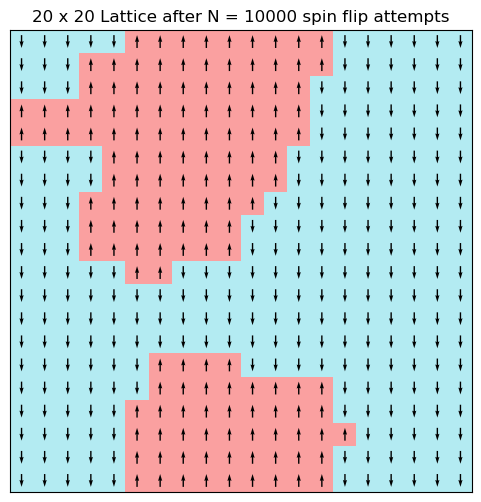

In [6]:
# perform the monte carlo
N = 10000
n = 20

my_lattice = createLattice(n)

for i in range(N):
    # perturb it
    dH, new_lattice = perturb(my_lattice)
    # check if it will accept the perturbation
    # if accept: new_lattice is the my_lattice
    # if not: my_lattice remains
    if willYouAccept(dH):
        my_lattice = new_lattice

# plot the result:

plt.figure(figsize = (6,6))
cmap = ListedColormap(["#B3EBF2", "#FAA0A0"])
plt.imshow(my_lattice, cmap = cmap, vmin = -1, vmax = 1, origin = 'lower', interpolation = 'nearest')

y, x = np.indices(my_lattice.shape)
plt.quiver(x, y, np.zeros_like(my_lattice), my_lattice, pivot = 'mid', angles = 'xy')
plt.xticks([])
plt.yticks([])
plt.title("20 x 20 Lattice after N = 10000 spin flip attempts")

## 3. Investigating Spontaneous Magnetization

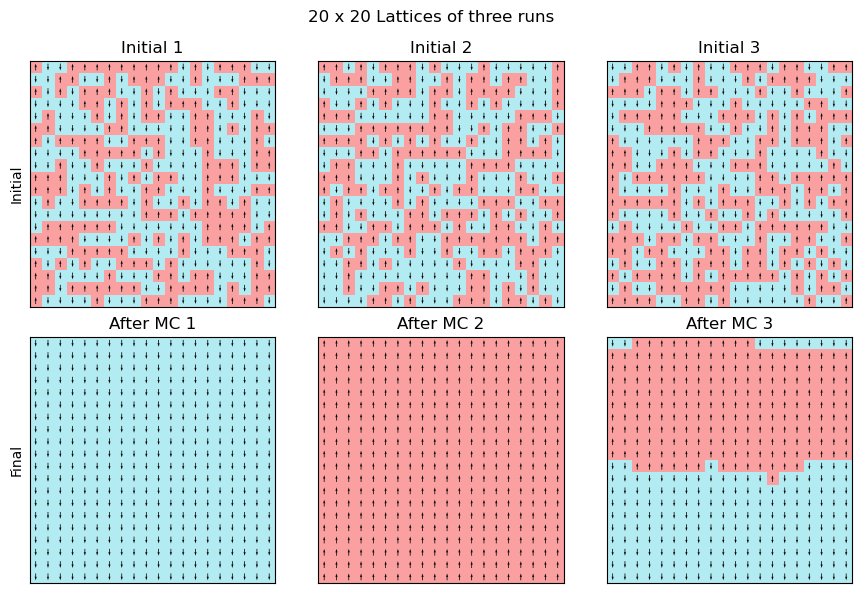

<Figure size 640x480 with 0 Axes>

In [20]:
# 1. Run the simulation for 10e4 - 10e6 attempted spin flips, you decide what's appropriate
# 2. Record the magnetization per spin and total energy throughout the simulation;

#-----------------------------------
# sandbox for recording magnetization

# to record total magnetization we calculate it as M = sum of all elements
# to record average magnetization per spin it is m = M/N^2
# to be efficient we can just record M as an array and then calculate m from there

# create a recording array for M
#-----------------------------------

# just copying the code from above, turning it into a function so that I can run multiple configurations

def monteCarlo(my_lattice, N = 1e5):

    # storage arrays:
    M = [] # for total magnetization

    N = int(1e5)
    n = 20

    for i in range(N):
        # perturb it
        dH, new_lattice = perturb(my_lattice)
        # check if it will accept the perturbation
        # if accept: new_lattice is the my_lattice
        # if not: my_lattice remains
        if willYouAccept(dH):
            my_lattice = new_lattice

        M.append(np.sum(my_lattice)) # get the total magnetization for each step

    # then we can calculate the average magnetization per spin
    M = np.array(M)
    m = M/(n**2)

    return my_lattice, M, m

# make drawing a lattice a function so i can call it many times

def drawLattice(ax, lattice, title=None):
    cmap = ListedColormap(["#B3EBF2", "#FAA0A0"])
    ax.imshow(lattice, cmap=cmap, vmin=-1, vmax=1, origin='lower', interpolation='nearest')
    y, x = np.indices(lattice.shape)
    ax.quiver(x, y, np.zeros_like(lattice), lattice, pivot='mid', angles='xy')
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title)


n = 20
initial_lattices = [createLattice(n) for _ in range(3)]

final_lattices, M_runs, m_runs = [], [], []
for lat in initial_lattices:
    final, M, m = monteCarlo(lat)
    final_lattices.append(final)
    M_runs.append(M)
    m_runs.append(m)

fig, axs = plt.subplots(2, 3, figsize=(9, 6))
for k in range(3):
    drawLattice(axs[0, k], initial_lattices[k], f"Initial {k+1}")
    drawLattice(axs[1, k], final_lattices[k], f"After MC {k+1}")
axs[0, 0].set_ylabel("Initial")
axs[1, 0].set_ylabel("Final")
fig.suptitle("20 x 20 Lattices of three runs")
fig.tight_layout()
plt.show()
plt.savefig("wow.png")

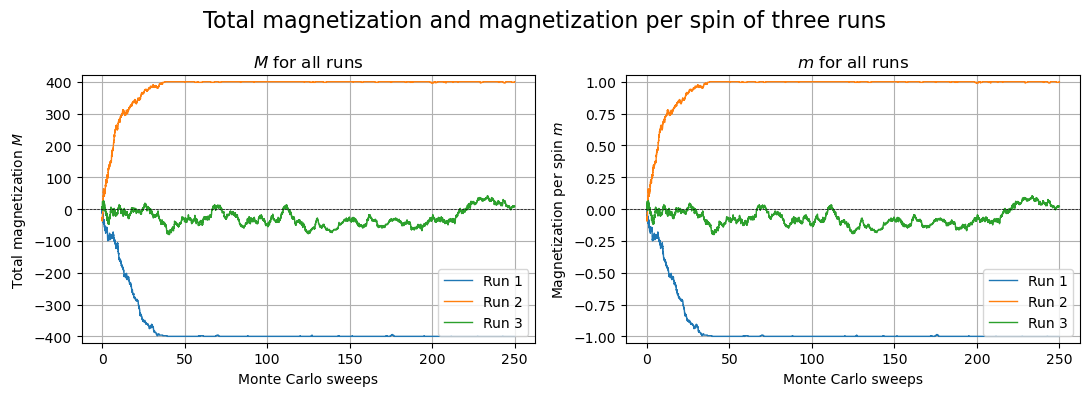

In [21]:
fig2, (ax_M, ax_m) = plt.subplots(1, 2, figsize=(11, 4))

# M and m were recorded after every attempted flip
# n^2 lattice, so n^2 attempts is one "sweep"
sweeps = np.arange(1, len(M_runs[0]) + 1) / n**2

for k in range(len(M_runs)):
    ax_M.plot(sweeps, M_runs[k], lw=1, label=f"Run {k+1}")
    ax_m.plot(sweeps, m_runs[k], lw=1, label=f"Run {k+1}")

ax_M.set_xlabel("Monte Carlo sweeps")
ax_M.set_ylabel("Total magnetization $M$")
ax_M.set_title("$M$ for all runs")
ax_M.set_ylim(-n**2 * 1.05, n**2 * 1.05)

ax_m.set_xlabel("Monte Carlo sweeps")
ax_m.set_ylabel("Magnetization per spin $m$")
ax_m.set_title("$m$ for all runs")
ax_m.set_ylim(-1.05, 1.05)

for ax in (ax_M, ax_m):
    ax.axhline(0, color="black", lw=0.5, ls="--")
    ax.legend()
    ax.grid()

fig2.suptitle("Total magnetization and magnetization per spin of three runs", fontsize = 16)
fig2.tight_layout()
plt.show()

## 4. Introducing an External Magnetic Field

([], [])

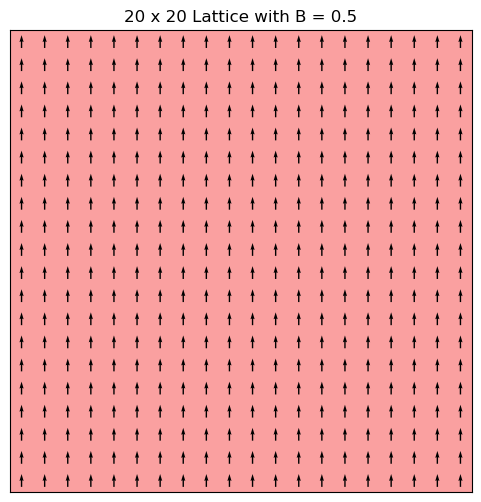

In [9]:
# Modify the Hamiltonian to include a uniform external magnetic field

# 1. Update the energy calculation and Metropolis algorithm

# consts
J = 1
B = 0.5
n = 20

def modifiedHamiltonian(lattice, J = 1, B = 0.5):
    # H = -J sum_ij [S_ij (S_i+1, j + S_i, j+1)

    # for S_i+1, j, we can shift i (row) by 1
    # since periodic boundary conditions, i can just put the topmost row to the bottom row (the next neighbor of bottomest row is the topmost row)
    lattice_row_shift = np.roll(lattice, shift = -1, axis = 0)
    
    # do the same for column shift, shift leftest column to the rightest part
    lattice_col_shift = np.roll(lattice, shift = -1, axis = 1)
    
    # total shift term sum
    shift_sum = lattice_row_shift + lattice_col_shift
    
    # note: element wise multiplication
    product = lattice * shift_sum
    
    # sum up all the elements
    H_term = -J * np.sum(product)

    # Now for the B term
    B_term = B * np.sum(lattice)

    return H_term - B_term

def modifiedPerturb(lattice):
    lattice2 = lattice.copy()

    rand_i = rng.integers(0,n)
    rand_j = rng.integers(0,n)

    random_spin = lattice2[rand_i, rand_j]
    lattice2[rand_i, rand_j] = random_spin * -1

    old_energy = modifiedHamiltonian(lattice)
    new_energy = modifiedHamiltonian(lattice2)

    dH = new_energy - old_energy

    return dH, lattice2

def modifiedMonteCarlo(my_lattice, N = 1e5):

    # storage arrays:
    M = [] # for total magnetization

    N = int(1e5)
    n = 20

    for i in range(N):
        # perturb it
        dH, new_lattice = modifiedPerturb(my_lattice)
        # check if it will accept the perturbation
        # if accept: new_lattice is the my_lattice
        # if not: my_lattice remains
        if willYouAccept(dH):
            my_lattice = new_lattice

        M.append(np.sum(my_lattice)) # get the total magnetization for each step

    # then we can calculate the average magnetization per spin
    M = np.array(M)
    m = M/(n**2)

    return my_lattice, M, m

# simulating
my_lattice = createLattice(n)
my_lattice, M, m = modifiedMonteCarlo(my_lattice)

plt.figure(figsize = (6,6))
cmap = ListedColormap(["#B3EBF2", "#FAA0A0"])
plt.imshow(my_lattice, cmap = cmap, vmin = -1, vmax = 1, origin = 'lower', interpolation = 'nearest')
plt.title("20 x 20 Lattice with B = 0.5")

y, x = np.indices(lattice.shape)
plt.quiver(x, y, np.zeros_like(my_lattice), my_lattice, pivot = 'mid', angles = 'xy')
plt.xticks([])
plt.yticks([])

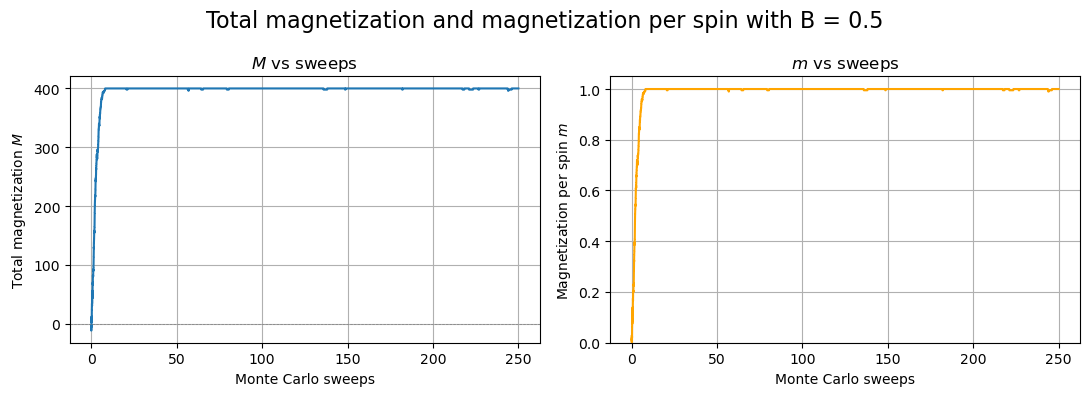

In [10]:
sweeps = np.arange(1, len(M) + 1) / n**2 

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].plot(sweeps, M)
axs[0].set_xlabel("Monte Carlo sweeps")
axs[0].set_ylabel("Total magnetization $M$")
axs[0].set_title("$M$ vs sweeps")

axs[1].plot(sweeps, m, color = 'orange')
axs[1].set_xlabel("Monte Carlo sweeps")
axs[1].set_ylabel("Magnetization per spin $m$")
axs[1].set_title("$m$ vs sweeps")
axs[1].set_ylim(0, 1.05)

for ax in axs:
    ax.axhline(0, color="gray", lw=0.5, ls="--")
    ax.grid()
    
fig.suptitle("Total magnetization and magnetization per spin with B = 0.5", fontsize = 16)
fig.tight_layout()

plt.show()

## 5. Critical Temperature

In [11]:
# Previously, T = 1, Redo Sections 2, 3, and 4, by selecting a temperature above Tc

# consts
J = 1
kB = 1
T_new = 5 * J / kB

### Section 2 Retry

Text(0.5, 1.0, '20 x 20 Lattice after N = 10000 spin flip attempts')

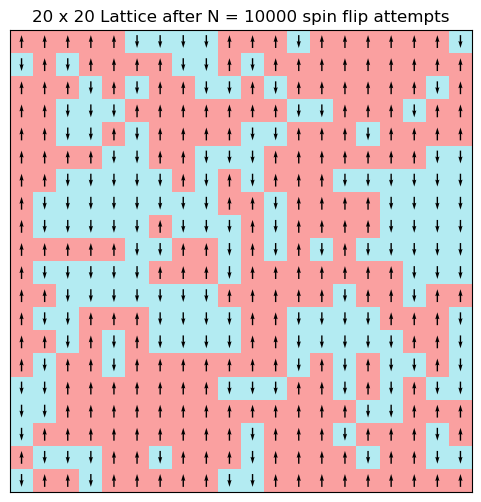

In [12]:
# perform the monte carlo
N = 10000
n = 20

my_lattice = createLattice(n)

for i in range(N):
    # perturb it
    dH, new_lattice = perturb(my_lattice)
    # check if it will accept the perturbation
    # if accept: new_lattice is the my_lattice
    # if not: my_lattice remains
    if willYouAccept(dH, T_new):
        my_lattice = new_lattice

# plot the result:

plt.figure(figsize = (6,6))
cmap = ListedColormap(["#B3EBF2", "#FAA0A0"])
plt.imshow(my_lattice, cmap = cmap, vmin = -1, vmax = 1, origin = 'lower', interpolation = 'nearest')

y, x = np.indices(my_lattice.shape)
plt.quiver(x, y, np.zeros_like(my_lattice), my_lattice, pivot = 'mid', angles = 'xy')
plt.xticks([])
plt.yticks([])
plt.title("20 x 20 Lattice after N = 10000 spin flip attempts")

### Section 3 Retry

### Section 4 Retry

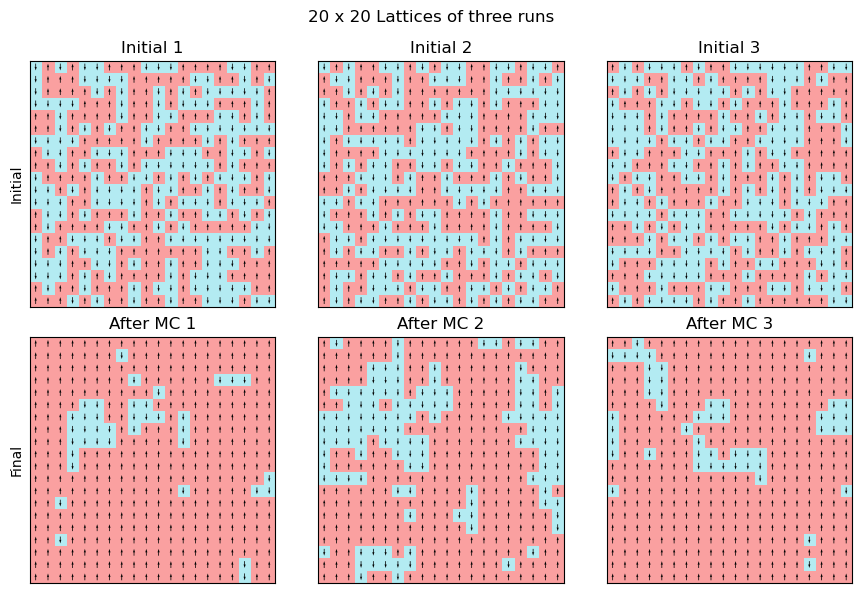

<Figure size 640x480 with 0 Axes>

In [13]:
# 1. Run the simulation for 10e4 - 10e6 attempted spin flips, you decide what's appropriate
# 2. Record the magnetization per spin and total energy throughout the simulation;

#-----------------------------------
# sandbox for recording magnetization

# to record total magnetization we calculate it as M = sum of all elements
# to record average magnetization per spin it is m = M/N^2
# to be efficient we can just record M as an array and then calculate m from there

# create a recording array for M
#-----------------------------------

# just copying the code from above, turning it into a function so that I can run multiple configurations

T_new = 2.27 * J / kB

def monteCarlo(my_lattice, N = 1e5):

    # storage arrays:
    M = [] # for total magnetization

    N = int(1e5)
    n = 20

    for i in range(N):
        # perturb it
        dH, new_lattice = perturb(my_lattice)
        # check if it will accept the perturbation
        # if accept: new_lattice is the my_lattice
        # if not: my_lattice remains
        if willYouAccept(dH, T_new):
            my_lattice = new_lattice

        M.append(np.sum(my_lattice)) # get the total magnetization for each step

    # then we can calculate the average magnetization per spin
    M = np.array(M)
    m = M/(n**2)

    return my_lattice, M, m

# make drawing a lattice a function so i can call it many times

def drawLattice(ax, lattice, title=None):
    cmap = ListedColormap(["#B3EBF2", "#FAA0A0"])
    ax.imshow(lattice, cmap=cmap, vmin=-1, vmax=1, origin='lower', interpolation='nearest')
    y, x = np.indices(lattice.shape)
    ax.quiver(x, y, np.zeros_like(lattice), lattice, pivot='mid', angles='xy')
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title)


n = 20
initial_lattices = [createLattice(n) for _ in range(3)]

final_lattices, M_runs, m_runs = [], [], []
for lat in initial_lattices:
    final, M, m = monteCarlo(lat)
    final_lattices.append(final)
    M_runs.append(M)
    m_runs.append(m)

fig, axs = plt.subplots(2, 3, figsize=(9, 6))
for k in range(3):
    drawLattice(axs[0, k], initial_lattices[k], f"Initial {k+1}")
    drawLattice(axs[1, k], final_lattices[k], f"After MC {k+1}")
axs[0, 0].set_ylabel("Initial")
axs[1, 0].set_ylabel("Final")
fig.suptitle("20 x 20 Lattices of three runs")
fig.tight_layout()
plt.show()
plt.savefig("wow2.png")

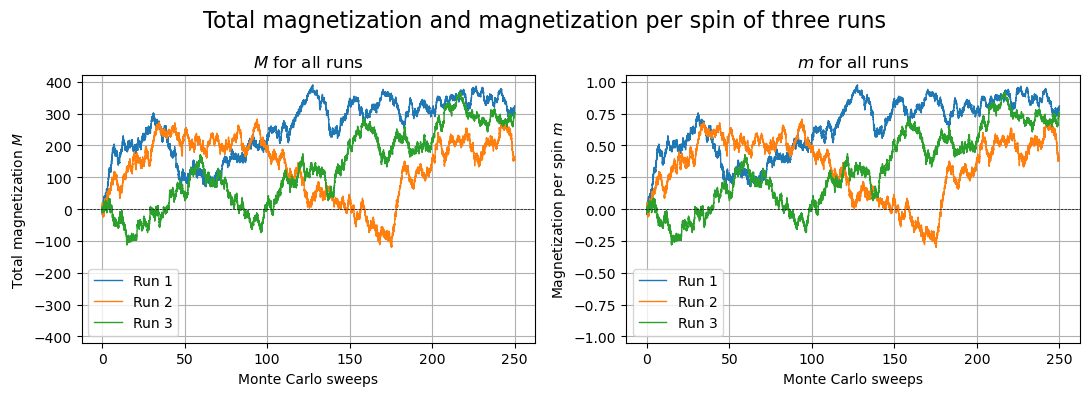

In [14]:
fig2, (ax_M, ax_m) = plt.subplots(1, 2, figsize=(11, 4))

# M and m were recorded after every attempted flip
# n^2 lattice, so n^2 attempts is one "sweep"
sweeps = np.arange(1, len(M_runs[0]) + 1) / n**2

for k in range(len(M_runs)):
    ax_M.plot(sweeps, M_runs[k], lw=1, label=f"Run {k+1}")
    ax_m.plot(sweeps, m_runs[k], lw=1, label=f"Run {k+1}")

ax_M.set_xlabel("Monte Carlo sweeps")
ax_M.set_ylabel("Total magnetization $M$")
ax_M.set_title("$M$ for all runs")
ax_M.set_ylim(-n**2 * 1.05, n**2 * 1.05)

ax_m.set_xlabel("Monte Carlo sweeps")
ax_m.set_ylabel("Magnetization per spin $m$")
ax_m.set_title("$m$ for all runs")
ax_m.set_ylim(-1.05, 1.05)

for ax in (ax_M, ax_m):
    ax.axhline(0, color="black", lw=0.5, ls="--")
    ax.legend()
    ax.grid()

fig2.suptitle("Total magnetization and magnetization per spin of three runs", fontsize = 16)
fig2.tight_layout()
plt.show()

([], [])

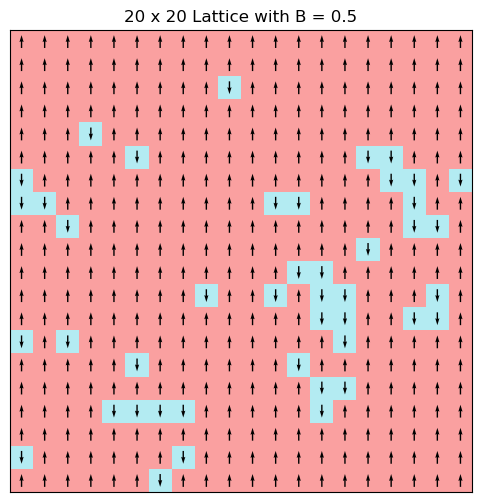

In [15]:
# Modify the Hamiltonian to include a uniform external magnetic field

# 1. Update the energy calculation and Metropolis algorithm

# consts
J = 1
B = 0.5
n = 20
T_new = 3 * J / kB

def modifiedHamiltonian(lattice, J = 1, B = 0.5):
    # H = -J sum_ij [S_ij (S_i+1, j + S_i, j+1)

    # for S_i+1, j, we can shift i (row) by 1
    # since periodic boundary conditions, i can just put the topmost row to the bottom row (the next neighbor of bottomest row is the topmost row)
    lattice_row_shift = np.roll(lattice, shift = -1, axis = 0)
    
    # do the same for column shift, shift leftest column to the rightest part
    lattice_col_shift = np.roll(lattice, shift = -1, axis = 1)
    
    # total shift term sum
    shift_sum = lattice_row_shift + lattice_col_shift
    
    # note: element wise multiplication
    product = lattice * shift_sum
    
    # sum up all the elements
    H_term = -J * np.sum(product)

    # Now for the B term
    B_term = B * np.sum(lattice)

    return H_term - B_term

def modifiedPerturb(lattice):
    lattice2 = lattice.copy()

    rand_i = rng.integers(0,n)
    rand_j = rng.integers(0,n)

    random_spin = lattice2[rand_i, rand_j]
    lattice2[rand_i, rand_j] = random_spin * -1

    old_energy = modifiedHamiltonian(lattice)
    new_energy = modifiedHamiltonian(lattice2)

    dH = new_energy - old_energy

    return dH, lattice2

def modifiedMonteCarlo(my_lattice, N = 1e5):

    # storage arrays:
    M = [] # for total magnetization

    N = int(1e5)
    n = 20

    for i in range(N):
        # perturb it
        dH, new_lattice = modifiedPerturb(my_lattice)
        # check if it will accept the perturbation
        # if accept: new_lattice is the my_lattice
        # if not: my_lattice remains
        if willYouAccept(dH, T_new):
            my_lattice = new_lattice

        M.append(np.sum(my_lattice)) # get the total magnetization for each step

    # then we can calculate the average magnetization per spin
    M = np.array(M)
    m = M/(n**2)

    return my_lattice, M, m

# simulating
my_lattice = createLattice(n)
my_lattice, M, m = modifiedMonteCarlo(my_lattice)

plt.figure(figsize = (6,6))
cmap = ListedColormap(["#B3EBF2", "#FAA0A0"])
plt.imshow(my_lattice, cmap = cmap, vmin = -1, vmax = 1, origin = 'lower', interpolation = 'nearest')
plt.title("20 x 20 Lattice with B = 0.5")

y, x = np.indices(lattice.shape)
plt.quiver(x, y, np.zeros_like(my_lattice), my_lattice, pivot = 'mid', angles = 'xy')
plt.xticks([])
plt.yticks([])

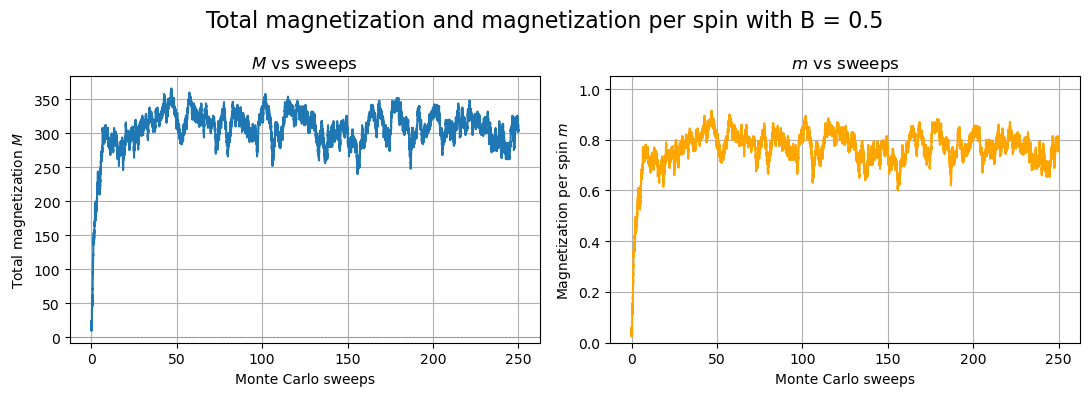

In [16]:
sweeps = np.arange(1, len(M) + 1) / n**2 

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].plot(sweeps, M)
axs[0].set_xlabel("Monte Carlo sweeps")
axs[0].set_ylabel("Total magnetization $M$")
axs[0].set_title("$M$ vs sweeps")

axs[1].plot(sweeps, m, color = 'orange')
axs[1].set_xlabel("Monte Carlo sweeps")
axs[1].set_ylabel("Magnetization per spin $m$")
axs[1].set_title("$m$ vs sweeps")
axs[1].set_ylim(0, 1.05)

for ax in axs:
    ax.axhline(0, color="gray", lw=0.5, ls="--")
    ax.grid()
    
fig.suptitle("Total magnetization and magnetization per spin with B = 0.5", fontsize = 16)
fig.tight_layout()

plt.show()